# 🍷 Wine Quality Prediction — Data Ingestion & Structural Inspection
**Oasis Infobyte Data Analytics Internship — Task Level 2 (Task 2)**  
**Author:** Adarsh  
**Environment:** Python 3.14 | pandas | numpy | scikit-learn | matplotlib | seaborn  
**Dataset Source:** [UCI Machine Learning Repository: Wine Quality Dataset](https://archive.ics.uci.edu/dataset/186/wine+quality) (Cortez et al., 2009)

---

## 📌 Objectives & Scope
The primary goal of this project is to build and evaluate predictive classification models that determine wine quality scores based on physicochemical laboratory tests.

### Key Focus Areas:
1. **Environment Setup & Data Ingestion:** Load physicochemical datasets for red and white wine variants.
2. **Dataset Architecture & Structural Audit:** Profile dataset dimensions, column data types, memory footprint, missing values, and duplicate records.
3. **Descriptive Statistics:** Calculate five-number summaries, central tendencies, standard deviations, and Interquartile Ranges (IQR).
4. **Target Variable Analysis:** Check frequency distributions and percentage representations across quality rating levels (scale 3–8).
5. **Class Imbalance Diagnostics:** Quantify severe class skewness and delineate core implications for downstream modeling (stratification, evaluation metrics, and target binning).

## 1. Setup & Library Imports

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting aesthetics
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

print(f'Python Version: {sys.version.split()[0]}')
print(f'Pandas Version: {pd.__version__}')
print(f'NumPy Version:  {np.__version__}')
print('Libraries successfully imported!')

Python Version: 3.14.8
Pandas Version: 3.0.6
NumPy Version:  2.5.3
Libraries successfully imported!


## 2. Ingesting the Wine Quality Datasets
The dataset is stored in comma/semicolon delimited format from the UCI repository. We load both the Red Wine dataset (`winequality-red.csv`) and White Wine dataset (`winequality-white.csv`).

In [2]:
# Locate and load dataset
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / 'Data' if (BASE_DIR / 'Data').exists() else BASE_DIR.parent / 'Data'
red_path = DATA_DIR / 'winequality-red.csv'
white_path = DATA_DIR / 'winequality-white.csv'

print(f'Loading Red Wine dataset from:   {red_path.resolve()}')
df_red = pd.read_csv(red_path, sep=';')
print(f'Red Wine Dataset Loaded:        {df_red.shape[0]:,} rows, {df_red.shape[1]} columns')

print(f'Loading White Wine dataset from: {white_path.resolve()}')
df_white = pd.read_csv(white_path, sep=';')
print(f'White Wine Dataset Loaded:      {df_white.shape[0]:,} rows, {df_white.shape[1]} columns')

Loading Red Wine dataset from:   C:\Users\Iba Zaidi\Desktop\OIBSIP\DataAnalytics-L2-WineQuality\Data\winequality-red.csv
Red Wine Dataset Loaded:        1,599 rows, 12 columns
Loading White Wine dataset from: C:\Users\Iba Zaidi\Desktop\OIBSIP\DataAnalytics-L2-WineQuality\Data\winequality-white.csv
White Wine Dataset Loaded:      4,898 rows, 12 columns


In [3]:
# Preview first 5 records of the red wine dataset
df_red.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 3. Structural Integrity & Schema Inspection
Let us inspect the data types, non-null values, and memory usage for the red wine dataset.

In [4]:
# Detailed information summary
df_red.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


### 3.1 Missing Value and Duplicate Record Audit

In [5]:
# Missing value verification
null_counts = df_red.isnull().sum()
null_pct = (df_red.isnull().mean() * 100).round(2)
integrity_df = pd.DataFrame({'Null Count': null_counts, 'Null Percentage (%)': null_pct})
print('--- Missing Values Assessment ---')
print(integrity_df)

# Duplicate verification
dup_count = df_red.duplicated().sum()
dup_pct = (dup_count / len(df_red)) * 100
print(f'\n--- Duplicate Rows Assessment ---')
print(f'Duplicate records: {dup_count} ({dup_pct:.2f}% of total samples)')

--- Missing Values Assessment ---
                      Null Count  Null Percentage (%)
fixed acidity                  0                  0.0
volatile acidity               0                  0.0
citric acid                    0                  0.0
residual sugar                 0                  0.0
chlorides                      0                  0.0
free sulfur dioxide            0                  0.0
total sulfur dioxide           0                  0.0
density                        0                  0.0
pH                             0                  0.0
sulphates                      0                  0.0
alcohol                        0                  0.0
quality                        0                  0.0

--- Duplicate Rows Assessment ---
Duplicate records: 240 (15.01% of total samples)


## 4. Descriptive Statistics & Central Tendency
Evaluating the parametric and non-parametric summary statistics (mean, standard deviation, quartiles, and Interquartile Range) for all 12 attributes.

In [6]:
# Compute descriptive statistical profile
stats_summary = df_red.describe().T
stats_summary['IQR'] = stats_summary['75%'] - stats_summary['25%']
stats_summary['skewness'] = df_red.skew()
stats_summary['kurtosis'] = df_red.kurtosis()
stats_summary[['mean', 'std', 'min', '25%', '50%', '75%', 'max', 'IQR', 'skewness']].round(3)

,mean,std,min,25%,50%,75%,max,IQR,skewness
fixed acidity,8.320,1.741,4.600,7.100,7.900,9.200,15.900,2.100,0.983
volatile acidity,0.528,0.179,0.120,0.390,0.520,0.640,1.580,0.250,0.672
citric acid,0.271,0.195,0.000,0.090,0.260,0.420,1.000,0.330,0.318
residual sugar,2.539,1.410,0.900,1.900,2.200,2.600,15.500,0.700,4.541
chlorides,0.087,0.047,0.012,0.070,0.079,0.090,0.611,0.020,5.680
free sulfur dioxide,15.875,10.460,1.000,7.000,14.000,21.000,72.000,14.000,1.251
total sulfur dioxide,46.468,32.895,6.000,22.000,38.000,62.000,289.000,40.000,1.516
density,0.997,0.002,0.990,0.996,0.997,0.998,1.004,0.002,0.071
pH,3.311,0.154,2.740,3.210,3.310,3.400,4.010,0.190,0.194
sulphates,0.658,0.170,0.330,0.550,0.620,0.730,2.000,0.180,2.429


## 5. Target Variable Analysis: Quality Score Distribution
The target variable `quality` represents sensory evaluation scores rated by wine experts on a scale from 0 to 10 (with actual observed ratings between 3 and 8).

In [7]:
# Frequency distribution of quality ratings
quality_counts = df_red['quality'].value_counts().sort_index()
quality_pct = (quality_counts / len(df_red) * 100).round(2)

dist_table = pd.DataFrame({
    'Quality Rating': quality_counts.index,
    'Sample Count': quality_counts.values,
    'Percentage (%)': quality_pct.values,
    'Cumulative (%)': quality_pct.cumsum().round(2).values
})
dist_table

,Quality Rating,Sample Count,Percentage (%),Cumulative (%)
0,3,10,0.63,0.63
1,4,53,3.31,3.94
2,5,681,42.59,46.53
3,6,638,39.90,86.43
4,7,199,12.45,98.88
5,8,18,1.13,100.01


### 5.1 Visualizing Quality Class Frequencies
Generating an annotated frequency distribution plot displaying sample counts and percentage representation across all quality grades.

Figure saved to: C:\Users\Iba Zaidi\Desktop\OIBSIP\DataAnalytics-L2-WineQuality\reports\figures\day1_quality_distribution.png


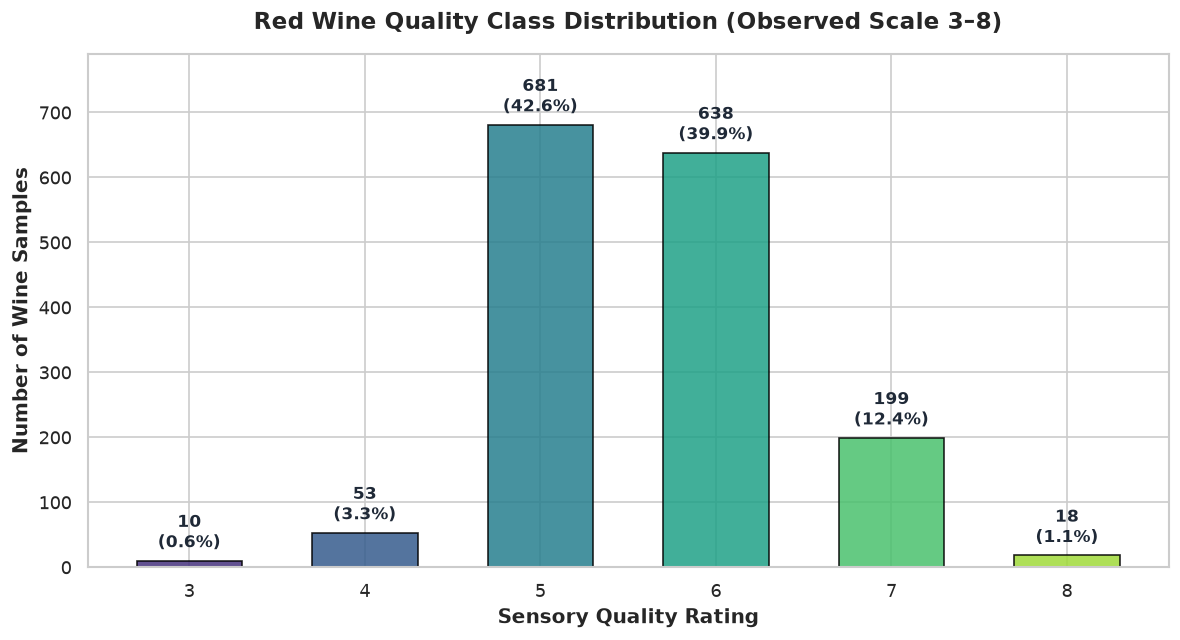

In [8]:
# Visualizing Class Distribution
fig, ax = plt.subplots(figsize=(10, 5.5))
colors = sns.color_palette('viridis', n_colors=len(quality_counts))
bars = ax.bar(quality_counts.index, quality_counts.values, color=colors, edgecolor='black', alpha=0.85, width=0.6)

ax.set_title('Red Wine Quality Class Distribution (Observed Scale 3–8)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Sensory Quality Rating', fontsize=12, fontweight='bold')
ax.set_ylabel('Number of Wine Samples', fontsize=12, fontweight='bold')
ax.set_xticks(quality_counts.index)
ax.set_ylim(0, max(quality_counts.values) * 1.16)

# Annotate bars with exact count and percentage
for bar, count in zip(bars, quality_counts.values):
    pct = (count / len(df_red)) * 100
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        bar.get_height() + 12,
        f'{count:,}\n({pct:.1f}%)',
        ha='center', va='bottom', fontsize=10, fontweight='bold', color='#1f2937'
    )

# Save figure
FIGURES_DIR = BASE_DIR / 'reports' / 'figures' if (BASE_DIR / 'reports').exists() else BASE_DIR.parent / 'reports' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig_path = FIGURES_DIR / 'day1_quality_distribution.png'
plt.tight_layout()
plt.savefig(fig_path, dpi=300)
print(f'Figure saved to: {fig_path.resolve()}')
plt.show()

### 5.2 Comparative Target Distribution: Red vs. White Wine
Comparing the relative distribution of sensory quality scores between the Red (1,599 samples) and White (4,898 samples) wine datasets.

In [9]:
# Comparative proportion analysis
comp_df = pd.DataFrame({
    'Red Wine (%)': (df_red['quality'].value_counts(normalize=True) * 100).round(2),
    'White Wine (%)': (df_white['quality'].value_counts(normalize=True) * 100).round(2)
}).sort_index().fillna(0.0)

comp_df['Total Proportional Delta'] = (comp_df['Red Wine (%)'] - comp_df['White Wine (%)']).round(2)
comp_df

,Red Wine (%),White Wine (%),Total Proportional Delta
quality,,,
3,0.63,0.41,0.22
4,3.31,3.33,-0.02
5,42.59,29.75,12.84
6,39.90,44.88,-4.98
7,12.45,17.97,-5.52
8,1.13,3.57,-2.44
9,0.00,0.10,-0.10


## 6. Key Analytical Findings & Class Imbalance Discussion

### Structural Data Findings:
1. **Complete Data Integrity:** Zero null, NaN, or unrecorded values exist across all 12 columns in both the Red and White wine datasets.
2. **Feature Types:** All 11 chemical predictors (`fixed acidity`, `volatile acidity`, `citric acid`, `residual sugar`, `chlorides`, `free sulfur dioxide`, `total sulfur dioxide`, `density`, `pH`, `sulphates`, `alcohol`) are continuous numerical floats (`float64`). The target (`quality`) is discrete integer (`int64`).
3. **Duplicate Rows:** 240 identical physicochemical profiles exist in red wine (15.01%). In enology, multiple batches or repeated laboratory assay measurements can share identical chemical signatures. Preserving these records reflects real-world sample prevalence.

### Severe Class Imbalance Diagnostics:
1. **Dominance of Average Quality:** Scores **5** (42.59%) and **6** (39.90%) constitute **82.49%** of the entire red wine corpus (1,319 of 1,599 observations).
2. **Scarcity of Extremes:**
   - Low Quality: Score 3 has only 10 samples (0.63%), Score 4 has 53 samples (3.31%).
   - High Quality: Score 7 has 199 samples (12.45%), Score 8 has only 18 samples (1.13%).
   - Scores < 3 or > 8 do not appear in the dataset.

### Direct Implications on Machine Learning Modeling:
- **Accuracy Paradox:** A naive classifier that blindly predicts score 5 or 6 would achieve ~82.5% accuracy while completely failing to detect exceptional (score 8) or flawed (score 3) wines.
- **Mandatory Stratification:** Standard random train-test splitting would risk producing test folds with zero representation for minority classes (scores 3 and 8). Stratified sampling (`StratifiedKFold`, `train_test_split(stratify=y)`) is mandatory.
- **Target Engineering Rationale:** Because predicting 6 discrete, highly imbalanced classes directly causes severe boundary confusion, binning quality scores into binary (`Good` $\ge 7$ vs `Bad` $< 7$) or 3-tier (`Low` $\le 4$, `Medium` 5–6, `High` $\ge 7$) groups provides a statistically robust and operationally practical formulation for classification.